# 04 · The search for a hidden second allele

**Place in the argument.** Track 1, alternative explanation. It looks for the part of a
biallelic model that the coding filter could have missed.

**Main output.** The locus filter, REF/ALT regulatory predictions for the one surviving
candidate, and the structural closure from GO 2B. A negative here is bounded by what each assay
can see.

> **Sanitised output.** No coordinates and no variant identities. The locus is described by size
> and relative position.

## The biological question

When standard analysis finds **only one** clearly damaging allele in an MVA gene, the second
can be **regulatory**, **deep intronic** or **structural**. This disease has a history of exactly
that: in early PCS families only one coding mutation per family was found
([Matsuura et al. 2006](https://doi.org/10.1002/ajmg.a.31069)), and later cases located the
hidden allele outside the exons, as an intronic insertion plus a promoter-region variant
([Kato et al. 2017](https://doi.org/10.1038/hgv.2017.21)) or as an intronic insertion that
short-read genome sequencing missed and RNA-seq plus long reads found
([Kawakami et al. 2024](https://doi.org/10.1038/s10038-023-01211-8)).

**Is there a second allele that our coding pipeline cannot see?**

## Hypothesis and preregistration

`docs/DECISIONS.md` § *Hidden Second Allele*. Window: gene body ± ~100 kb, because **there is a
published human precedent** of a regulatory second allele tens of kb upstream; restricting the
search to the gene body would be conceptually wrong.

Order of elimination, from the cheapest filter to the most expensive: population frequency, call
quality, functional position, conservation and regulatory signal, and finally AlphaGenome.

**Prediction #4 said AlphaGenome would return a flat Δ, and it was written hoping to fail**, so
that a negative would be reportable rather than disappointing.

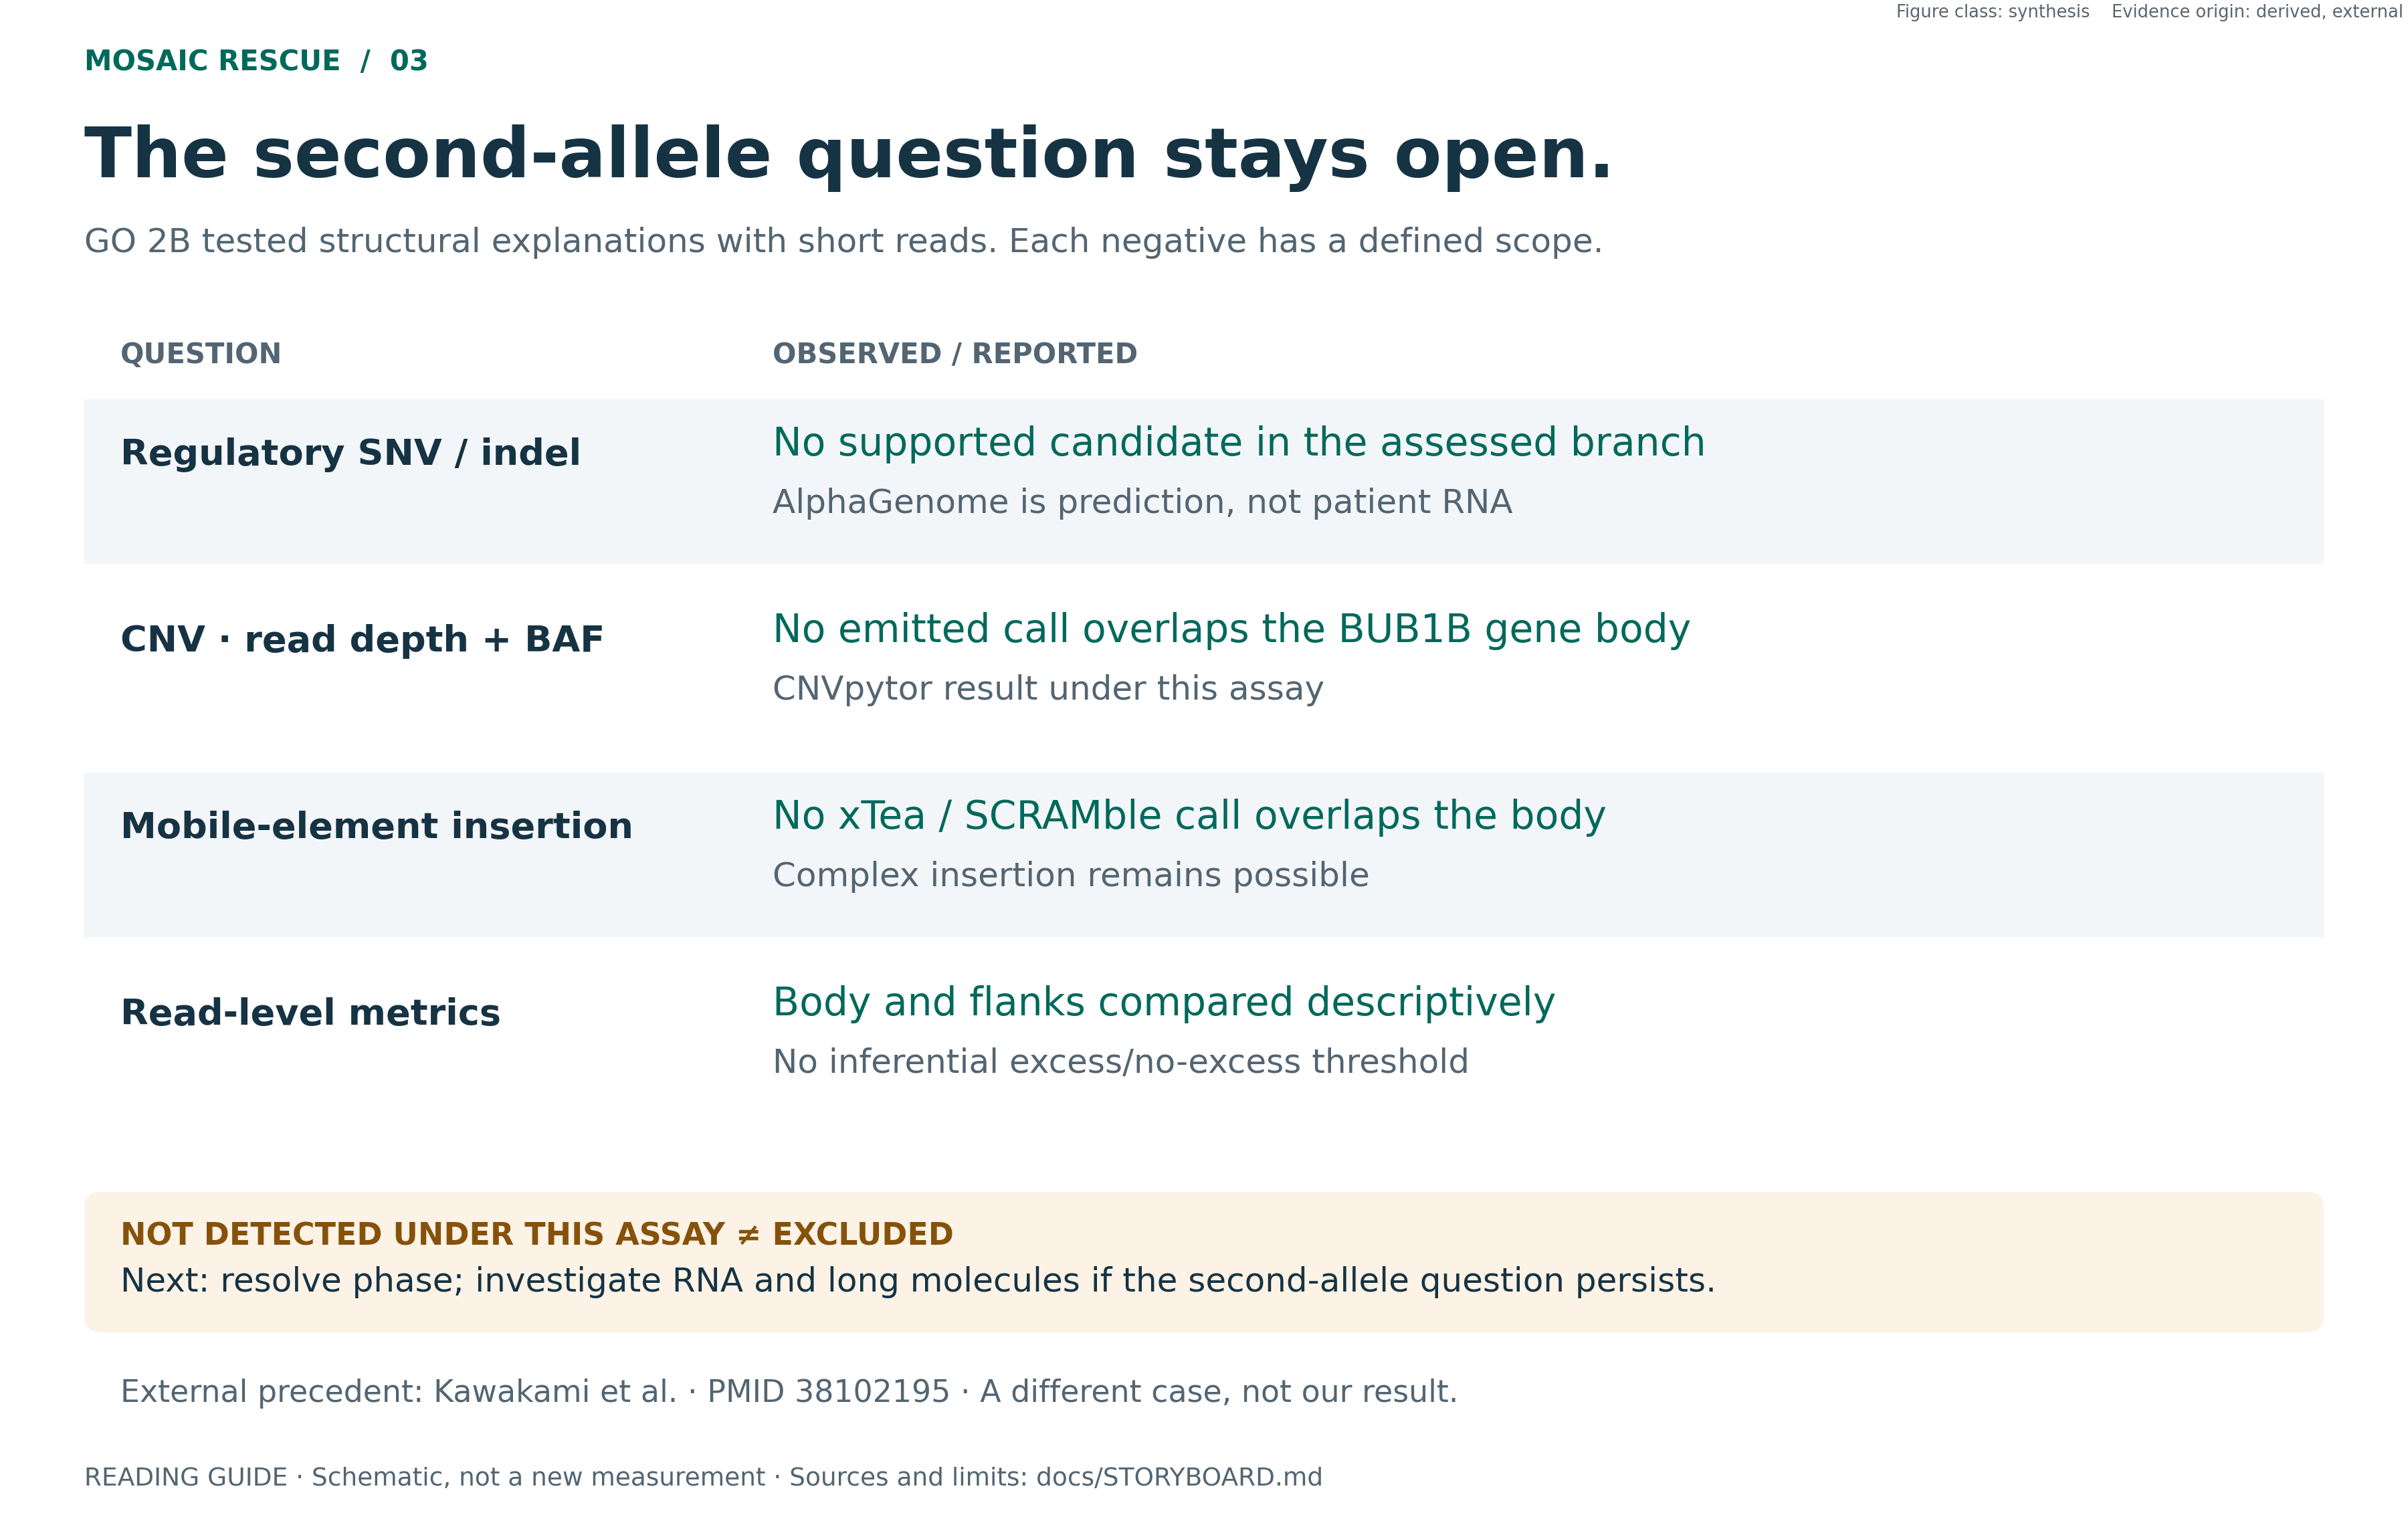

**`SYNTHESIS` · DERIVED / EXTERNAL.** GO 2B closure: no CNVpytor RD+BAF call and no xTea or SCRAMble MEI call overlaps the BUB1B gene body. A complex insertion is not excluded. Reviewed figure, embedded without re-running the original analysis · [sources and limits](../docs/STORYBOARD.md) · [figure QA](../PUBLICATION_FIGURE_QA.md)

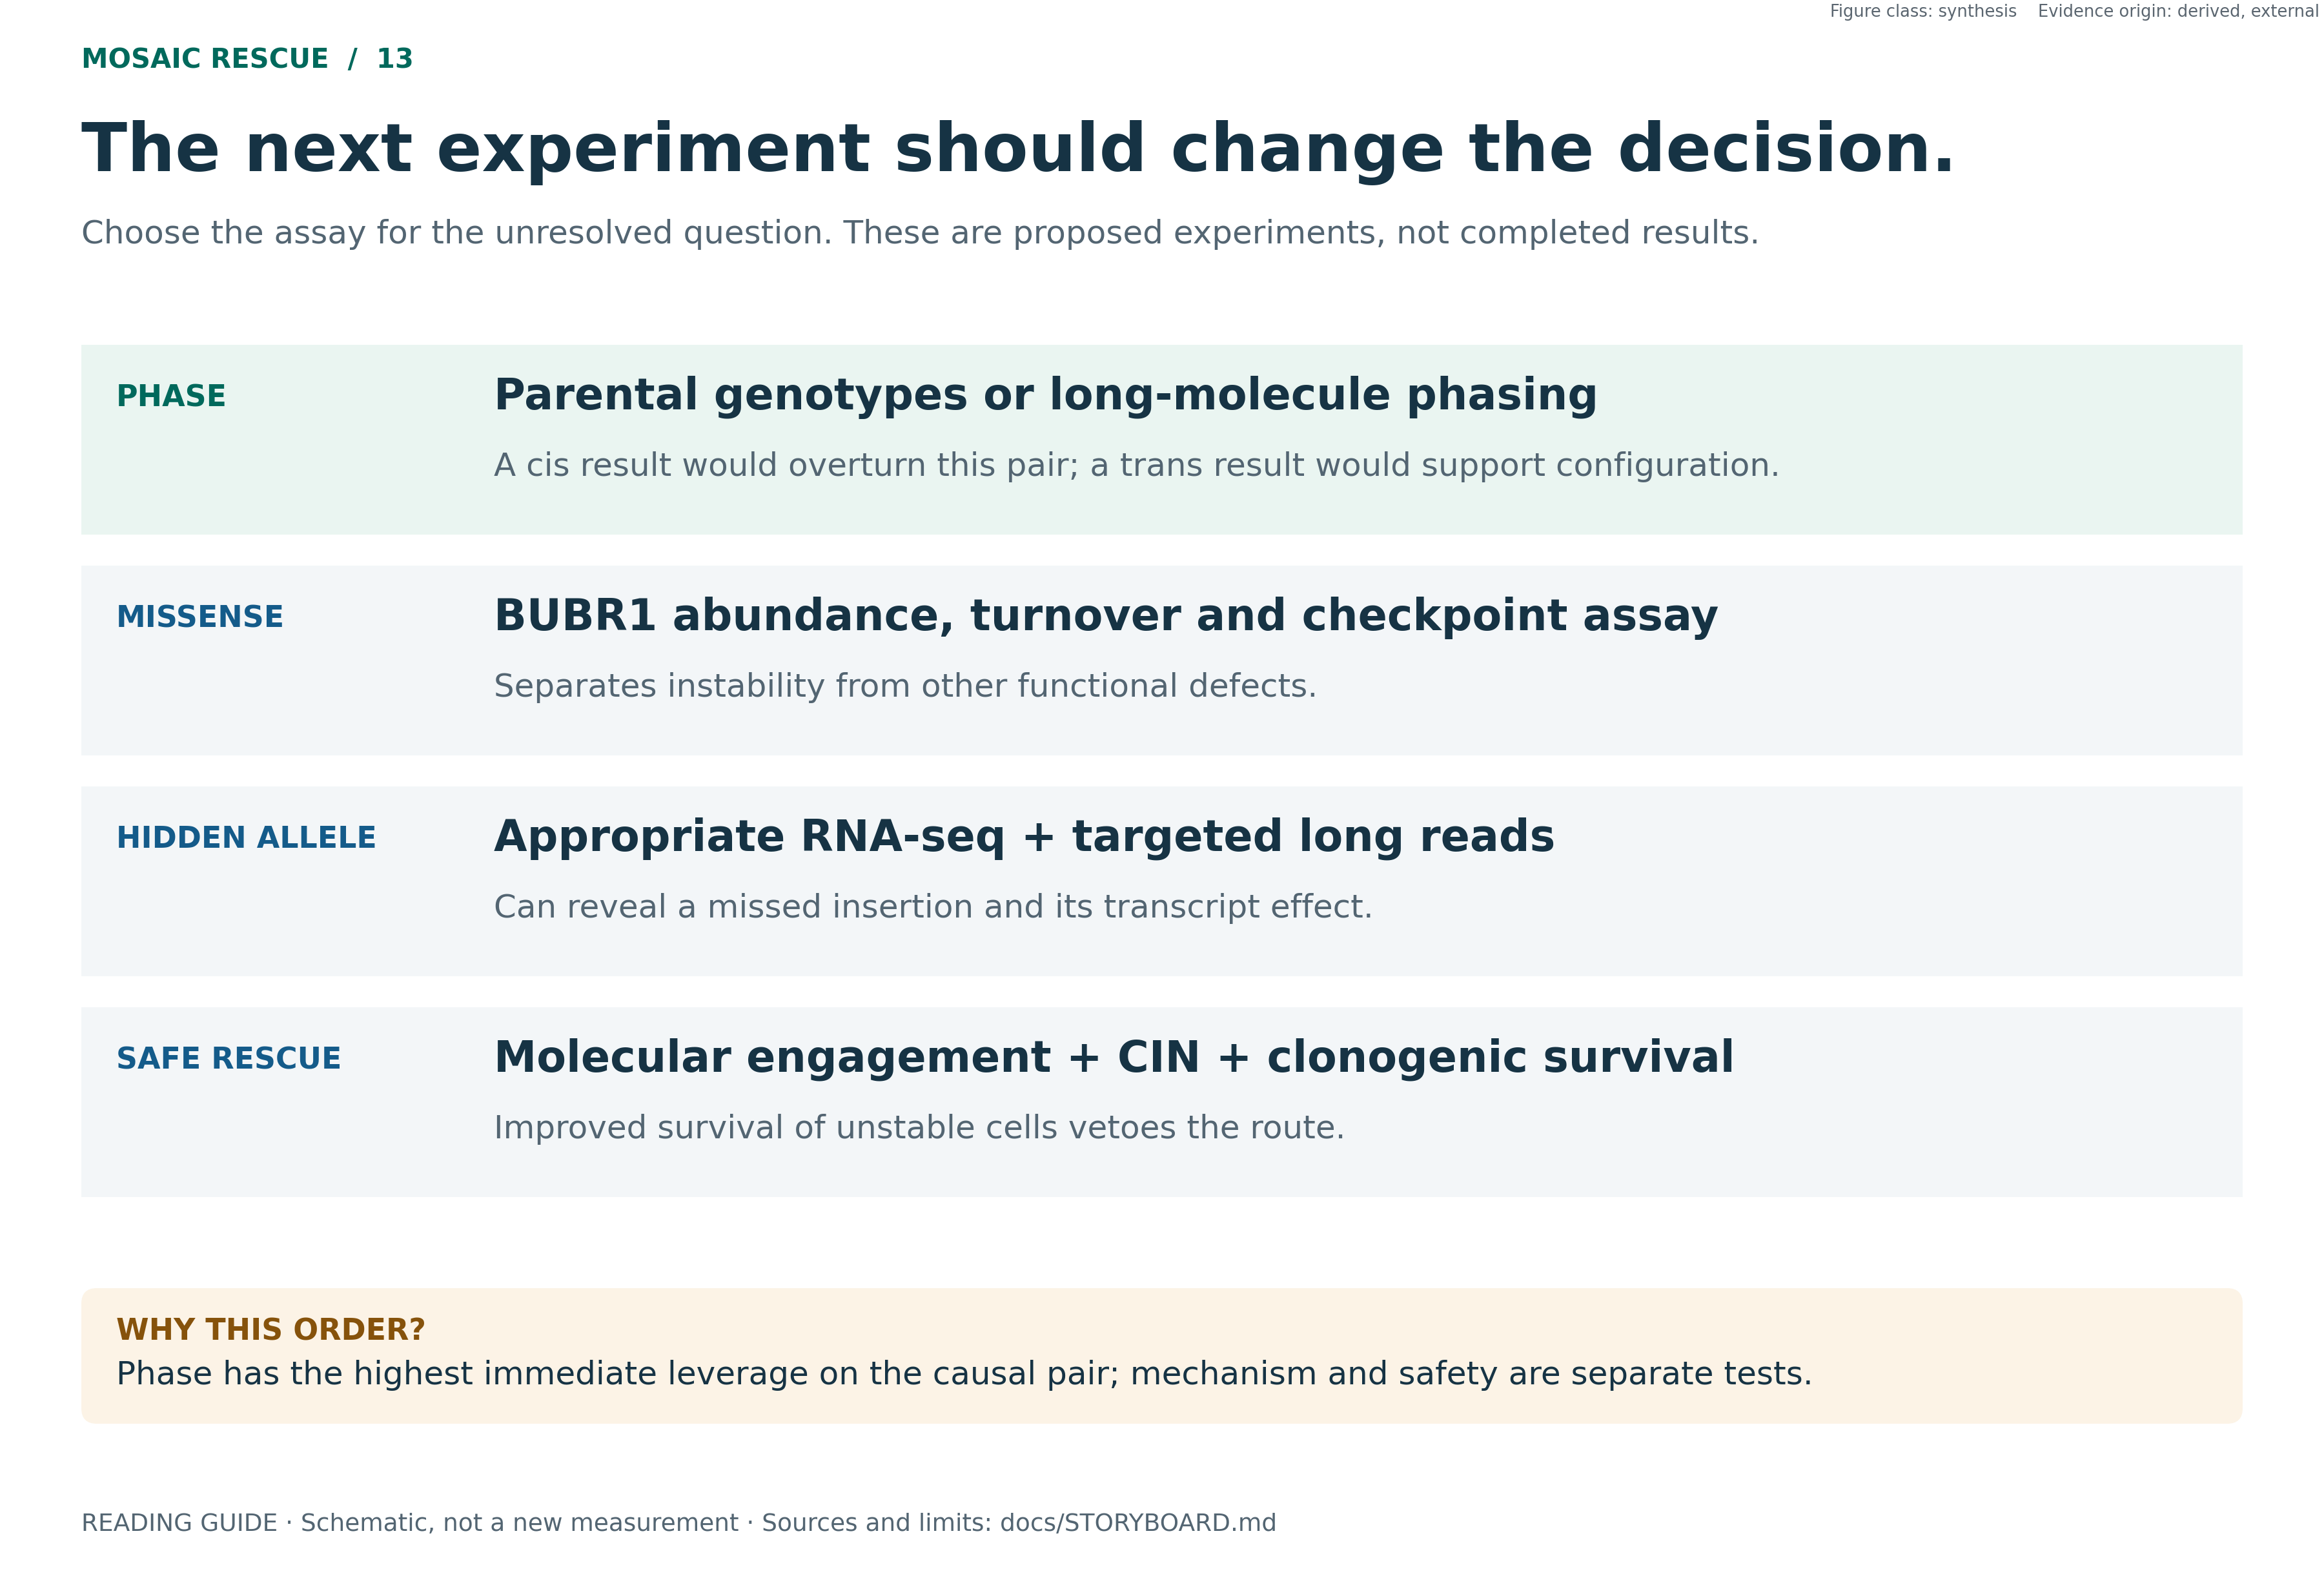

**`SYNTHESIS` · DERIVED / EXTERNAL.** RNA-seq and long reads are proposals. The AlphaGenome tracks below are existing predictions, not measured RNA and not a completed EXP-024 calibration. Reviewed figure, embedded without re-running the original analysis · [sources and limits](../docs/STORYBOARD.md) · [figure QA](../PUBLICATION_FIGURE_QA.md)

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # the pipeline uses paths relative to the repo root
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # inline figures + provenance captions
print("environment ready · figures in this notebook render inline, each with a provenance caption")

environment ready · figures in this notebook render inline, each with a provenance caption


In [2]:
fl.labels("What is observed", "Scope of the result")

## Method · the locus filter

| Stage | Variants |
|---|---:|
| in the extended locus (~270 kb) | 321 |
| after the population-frequency filter | 4 |
| rare, good quality, functional position | 1 |
| sent to AlphaGenome | 1 |
| with a relevant predicted Δ | **0** |

A single variant survived frequency, quality and functional position: a deep-intronic
heterozygous PASS call absent from gnomAD, without an rsID, more than 1 kb from the nearest exon
boundary. Prediction #1 failed on the high side (800 to 2 000 variants were expected; there were
321); it is recorded as a calibration failure of the prediction, not as a result.

This filter covers SNVs and indels in the window only. Structural variants are handled
separately below.

## Primary result · AlphaGenome on the single candidate

The tracks drawn here **were frozen before** the call was repeated, so the most flattering ones
could not be chosen after seeing them. So were the drawing rules: REF and ALT share their y
scale, and Δ sits in its own lane with zero visible.

**This was the only transmission of patient data off the machine in the whole project**,
planned in `docs/03_ALPHAGENOME_ASSESSMENT.md` §7. The shortlist was sent, never the VCF.

In [3]:
import glob
AG = glob.glob("work/alphagenome/chr*_A_G.json")[0]      # path not printed: it carries a coordinate
ag = json.load(io.open(AG, encoding="utf-8"))
mods = ag["modalities"]
print(f"  call status: {ag.get('status')}  ·  window: {ag.get('window_bp'):,} bp")
print()
print(f"  {'modality':<22}{'tracks':>8}{'rel. delta %':>14}{'max local delta':>18}")
for m in sorted(mods, key=lambda x: -abs(x["delta_rel"])):
    print(f"  {m['modalidad']:<22}{m['pistas']:>8}{m['delta_rel']:>14.3f}"
          f"{m['delta_local_max']:>18.4f}")
worst = max(abs(m["delta_rel"]) for m in mods)
spl = [m for m in mods if "splic" in m["modalidad"]]
print()
print(f"  largest relative delta of any modality : {worst:.2f} %")
if spl:
    print(f"  LOCAL delta of splice junctions        : "
          f"{min(m['delta_local_max'] for m in spl):.4f}")

  call status: PREDICTED  ·  window: 1,048,576 bp

  modality                tracks  rel. delta %   max local delta
  rna_seq                    667         0.034            0.1562
  chip_tf                   1617         0.022           96.0000
  dnase                      305         0.019            0.7500
  chip_histone              1116         0.018           16.0000
  atac                       167         0.013            0.1875
  splice_site_usage          734         0.012            0.0039
  splice_sites                 4         0.008            0.0063
  splice_junctions           367         0.004            0.0000

  largest relative delta of any modality : 0.03 %
  LOCAL delta of splice junctions        : 0.0000


### Main figure 1 · REF / ALT / Δ browser, track by track

The summary aggregates by modality. This view **aggregates nothing**: it draws the nine frozen
tracks as they came out of the model, on a **shared genomic axis**, with the gene model on top.

Two drawing rules, fixed before looking:

1. **REF and ALT share the exact y scale** within each track. Without this, any difference could
   be manufactured by rescaling.
2. **Δ sits in its own lane with zero visible** and a symmetric scale. Never overlaid.

> The x axis is **offset from the variant**, not an absolute coordinate.

In [4]:
AR = glob.glob("work/alphagenome/arrays_*.json")[0]
ar = json.load(io.open(AR, encoding="utf-8"))
TRK = ar["tracks"]
VPOS = ar["pos"]
FL = ar["flank_bp"]
print(f"  status: {ar['status']}  ·  window: +/-{FL:,} bp  ·  frozen tracks: {len(TRK)}")
for t in TRK:
    print(f"    {t['mod']:<20}{t['bp_per_bin']:>8.0f} bp/bin  {len(t['ref']):>6} bins   "
          f"{str(t['meta'])[:52]}")

from src.structure.transcript_model import fetch as fetch_tx
TX = fetch_tx()
EXW = [(e["start"] - VPOS, e["end"] - VPOS) for e in TX["exons"]
       if e["end"] > VPOS - FL and e["start"] < VPOS + FL]
print(f"  exons of {TX['transcript']} inside the window: {len(EXW)}")

  status: PREDICTED  ·  window: +/-5,000 bp  ·  frozen tracks: 9
    splice_sites               1 bp/bin   10000 bins   donor
    splice_site_usage          1 bp/bin   10000 bins   usage_CL:0000047 polyA plus RNA-seq · neuronal stem 
    splice_junctions         779 bp/bin      12 bins   junction_UBERON:0000473 gtex Testis polyA plus RNA-s
    chip_tf                  128 bp/bin      78 bins   CL:0002518 TF ChIP-seq CTCF · kidney epithelial cell
    chip_tf                  128 bp/bin      78 bins   CL:0002319 TF ChIP-seq RAD21 · neural cell
    rna_seq                    1 bp/bin   10000 bins   EFO:0002784 polyA plus RNA-seq · GM12878
    rna_seq                    1 bp/bin   10000 bins   EFO:0002067 polyA plus RNA-seq · K562
    atac                       1 bp/bin   10000 bins   CL:0000236 ATAC-seq · B cell
    dnase                      1 bp/bin   10000 bins   CL:0001059 DNase-seq · common myeloid progenitor, CD
  exons of ENST00000287598 inside the window: 5


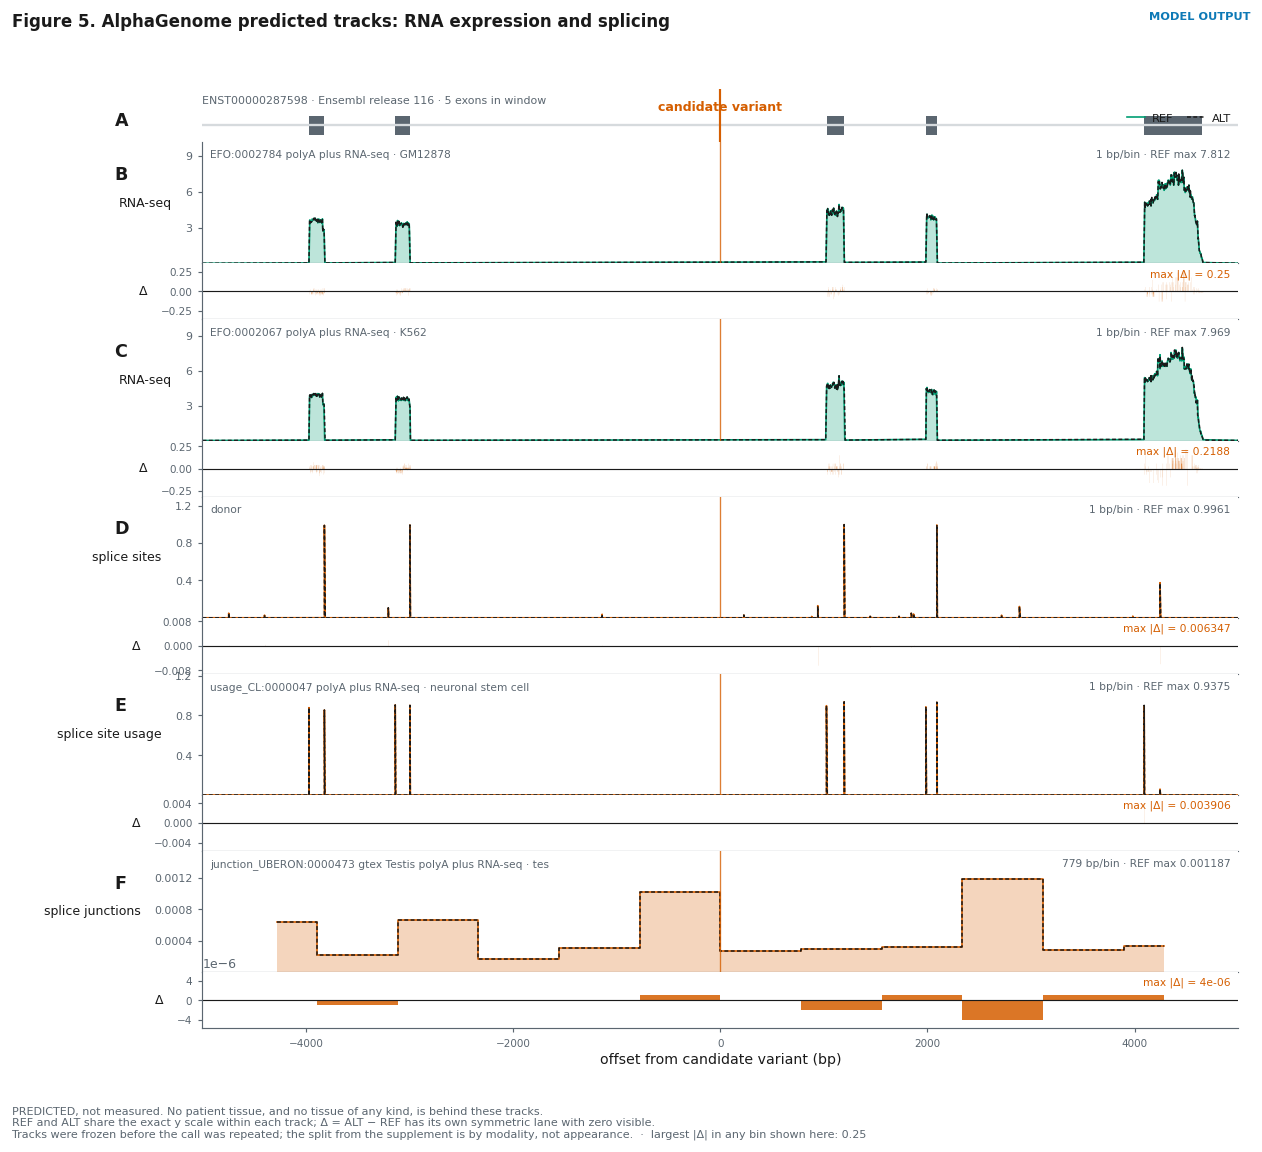

> **Main figure 1 · REF / ALT / delta browser: RNA expression and splicing**  
> `EXP-009` · figure class `MODEL_OUTPUT`, scientific figure · evidence origin `PREDICTED`  
> *What is observed.* 5 of the nine frozen tracks on the same genomic axis, with the gene model on top. REF and ALT share the exact y scale within each track and delta has its own lane with zero visible. The largest |delta| of any bin here is 0.25.  
> **Scope of the result.** that no second allele exists. It is a model PREDICTION for ONE SNV/indel candidate, not a measurement and not a scan. These tracks are NOT measured data from the patient or from any of the patient's tissues.  
> data: `work/alphagenome/arrays_*.json · tracks frozen before the call was repeated; the split between main and supplementary figure is by MODALITY` · library: `matplotlib` · provenance: `figures/pub/fig04_alphagenome_rna_splicing.svg + .png 300 dpi`

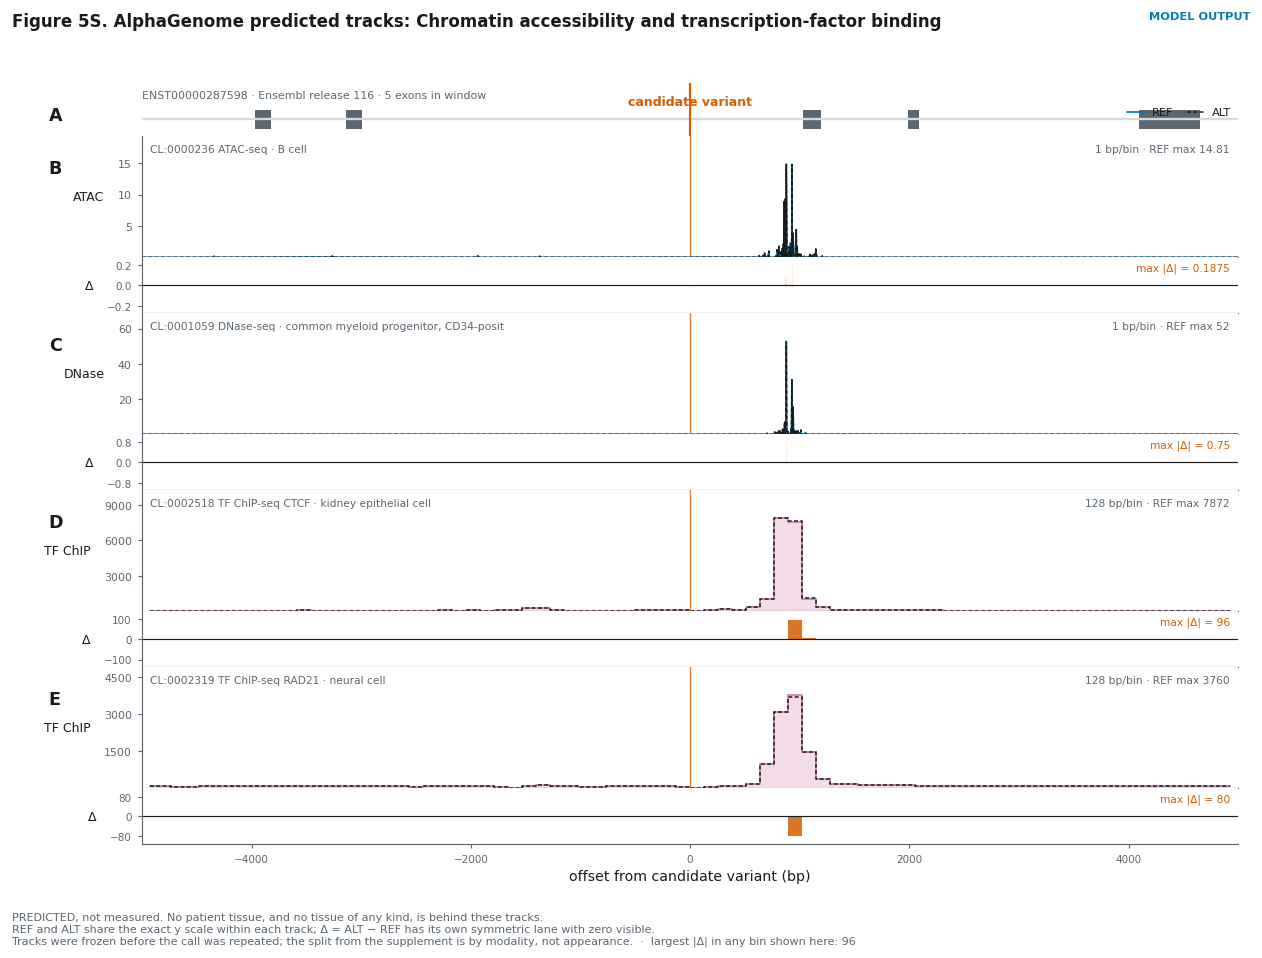

> **Supplementary figure 1S · REF / ALT / delta browser: Chromatin accessibility and transcription-factor binding**  
> `EXP-009` · figure class `MODEL_OUTPUT`, scientific figure · evidence origin `PREDICTED`  
> *What is observed.* 4 of the nine frozen tracks on the same genomic axis, with the gene model on top. REF and ALT share the exact y scale within each track and delta has its own lane with zero visible. The largest |delta| of any bin here is 96.  
> **Scope of the result.** that no second allele exists. It is a model PREDICTION for ONE SNV/indel candidate, not a measurement and not a scan. These tracks are NOT measured data from the patient or from any of the patient's tissues.  
> data: `work/alphagenome/arrays_*.json · tracks frozen before the call was repeated; the split between main and supplementary figure is by MODALITY` · library: `matplotlib` · provenance: `figures/pub/fig04S_alphagenome_accessibility_tf.svg + .png 300 dpi`

In [5]:
from src.figures import fig04_tracks as FT

_figs, _ar = FT.load_and_build()
for _which, _slug, _tag in (("main", "fig04_alphagenome_rna_splicing", "Main figure 1"),
                            ("supp", "fig04S_alphagenome_accessibility_tf", "Supplementary figure 1S")):
    _f, _st = _figs[_which]
    fl.pub(_f, f"{_tag} · REF / ALT / delta browser: {FT.GROUPS[_which]['title']}",
           "EXP-009", "PREDICTED", "MODEL_OUTPUT",
           f"{_st['n_tracks']} of the nine frozen tracks on the same genomic axis, with the gene "
           f"model on top. REF and ALT share the exact y scale within each track and delta has "
           f"its own lane with zero visible. The largest |delta| of any bin here is "
           f"{_st['max_abs_delta']:.4g}.",
           "that no second allele exists. It is a model PREDICTION for ONE SNV/indel candidate, "
           "not a measurement and not a scan. These tracks are NOT measured data from the "
           "patient or from any of the patient's tissues.",
           source="work/alphagenome/arrays_*.json · tracks frozen before the call was repeated; "
                  "the split between main and supplementary figure is by MODALITY",
           lib="matplotlib", slug=_slug)

### Post-freeze characterisation · in-silico mutagenesis and contact maps

**This is not new evidence and it reopens nothing.** It closes a question the browser leaves
open: *does the model respond to sequence changes in this neighbourhood, and does the candidate
fall where it responds?* And a second one: *does the predicted contact architecture change with
ALT?*

Both outputs were produced **on the same frozen candidate**, with a manifest written and sealed
with `sha256` **before** the first model call. The manifest fixes window, context, scorers,
ontology, biosample and the reading rule. The runners refuse to run if the manifest changes;
`src/verify.py` checks that the runs cite that same hash.

- **ISM:** 256 positions × 3 alternatives = 768 **synthetic** substitutions of the reference,
  scored with two readouts that mirror the block's split by modality: *splice sites* (primary,
  the modality that decided) and *DNase* on the already-frozen track (secondary). Predeclared
  rule: "concentrated local sensitivity" if the candidate is in the top 5 % of positions by
  |effect|. Context check at 100 kb, reported only.
- **Contacts:** REF, ALT and ALT − REF at 2 048 bp in a biosample chosen by criterion before
  predicting (primary fibroblast, the cell type of MVA functional studies). The 28 available
  biosamples are scored with the official scorer as context, never to choose.

Neither can raise the VUS, move the Track 1 ranking or become patient evidence. A negative here is
as reportable as a positive, and it is what came out.

In [6]:
MI = json.load(io.open("work/alphagenome/ism/metadata.json", encoding="utf-8"))
MC = json.load(io.open("work/alphagenome/contacts/metadata.json", encoding="utf-8"))
MAN = io.open("work/alphagenome/run_manifest.json.sha256").read().strip()
assert MI["manifest_sha256"] == MC["manifest_sha256"] == MAN, "runs made on different manifests"
print(f"  frozen manifest : sha256 {MAN[:12]}...  (cited by both runs)")
print(f"  ISM             : {MI['primary']['n_variants']} synthetic substitutions, "
      f"window {MI['primary']['ism_window_bp']} bp, context {MI['primary']['sequence_context_bp']:,} bp")
for _r, _i in MI["primary"]["roles"].items():
    _k = _i["ranks"]
    print(f"    {_r:<9} {_i['scorer']['output']:<13} candidate: position {_k['candidate_position_rank_of_L']:>3} of "
          f"{MI['primary']['ism_window_bp']} · substitution {_k['candidate_substitution_rank_of_all']:>3} of "
          f"{3 * MI['primary']['ism_window_bp']} · window maximum at {_k['window_argmax_offset']:+d} bp")
_ip = MI["interpretation"]
print(f"    predeclared reading: {_ip['reading']}")
print(f"    context r(16 kb, 100 kb): " + ", ".join(f"{k} {v:.2f}" for k, v in _ip["context_pearson_r"].items()))
_ic = MC["interpretation"]
print(f"  contacts        : {MC['biosample_name']} ({MC['ontology_curie']}), "
      f"{MC['n_bins']}x{MC['n_bins']} bins of {MC['output_resolution_bp']} bp")
print(f"    max |ALT-REF| / max REF = {100 * _ic['ratio']:.2f} % (predeclared threshold 5 %) -> "
      f"{_ic['reading']}")
print(f"    robustness: the predeclared track ranks {MC['robustness']['chosen_rank_of_n']} of "
      f"{MC['robustness']['n_tracks']} under the official scorer")

  frozen manifest : sha256 2709ed86c2b3...  (cited by both runs)
  ISM             : 768 synthetic substitutions, window 256 bp, context 16,384 bp
    PRIMARY   SPLICE_SITES  candidate: position  62 of 256 · substitution 251 of 768 · window maximum at +125 bp
    SECONDARY DNASE         candidate: position 168 of 256 · substitution 268 of 768 · window maximum at -109 bp
    predeclared reading: no compelling local ISM sensitivity under the pre-specified readout
    context r(16 kb, 100 kb): PRIMARY 0.95, SECONDARY 0.98
  contacts        : skin fibroblast (CL:0002620), 512x512 bins of 2048 bp
    max |ALT-REF| / max REF = 1.09 % (predeclared threshold 5 %) -> no compelling predicted contact effect
    robustness: the predeclared track ranks 8 of 28 under the official scorer


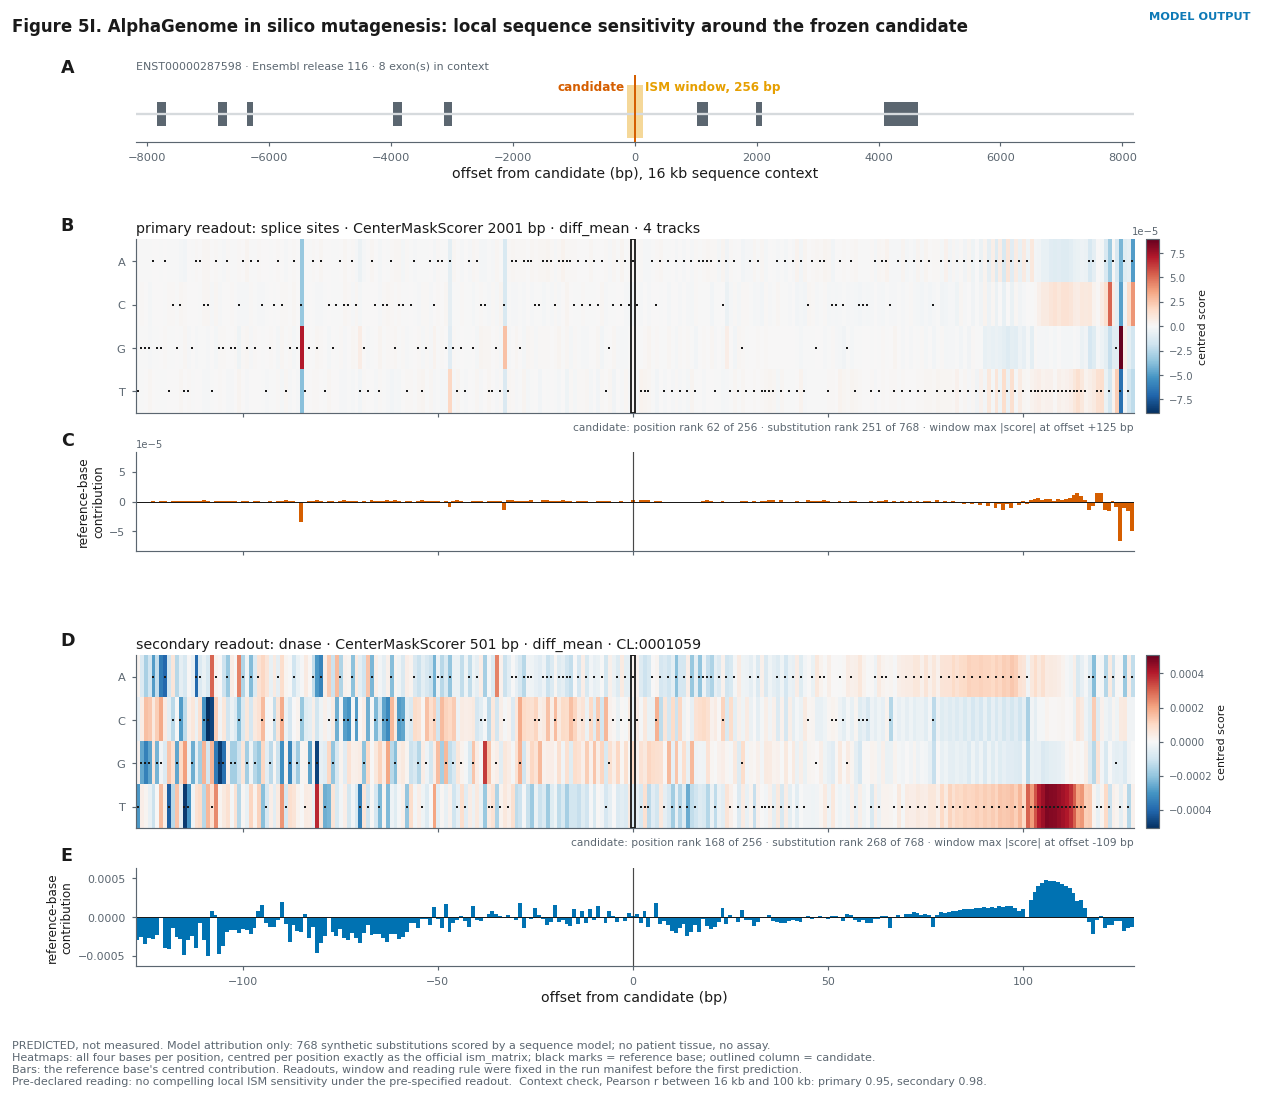

> **Main figure 2 · in-silico mutagenesis: the model's local sensitivity around the candidate**  
> `EXP-023` · figure class `MODEL_OUTPUT`, scientific figure · evidence origin `PREDICTED`  
> *What is observed.* 768 synthetic substitutions scored with two predeclared readouts. Under the primary (splice sites) the candidate is position 62 of 256 by |effect| and substitution 251 of 768; under the secondary (DNase), position 168. The window maximum is at +125 bp (primary) and -109 bp (secondary). Predeclared reading: no compelling local ISM sensitivity under the pre-specified readout. The 100 kb check reproduces the matrix (r = 0.95).  
> **Scope of the result.** that the region is or is not functional, that the variant is pathogenic or benign, or any regulatory mechanism in the patient. It is model ATTRIBUTION under a given scorer and context: it characterises the already-frozen negative and changes no classification or ranking.  
> data: `work/alphagenome/ism/*.json.gz + metadata.json · manifest sealed before the call` · library: `matplotlib` · provenance: `figures/pub/fig04I_alphagenome_ism.svg + .png 300 dpi`

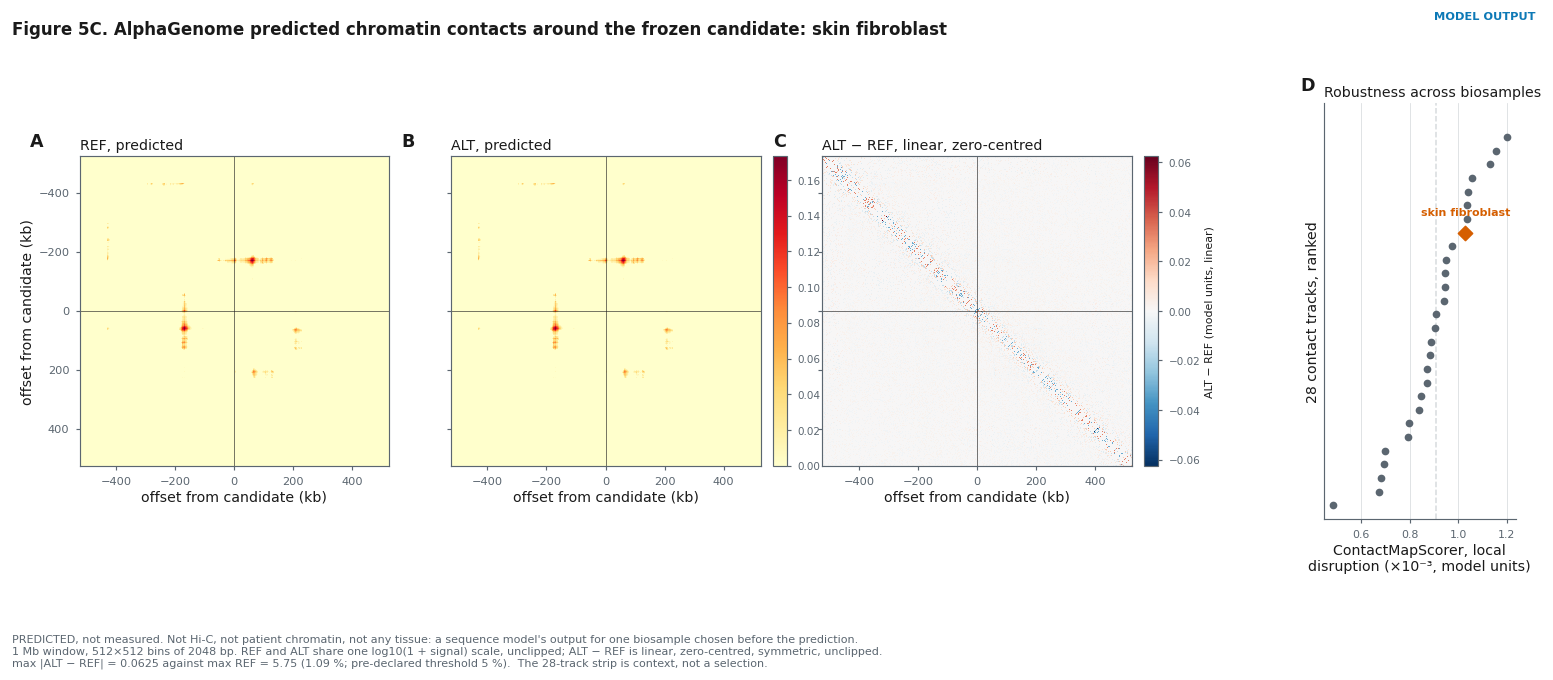

> **Supplementary figure 2C · predicted contact maps: REF, ALT and ALT - REF**  
> `EXP-023` · figure class `MODEL_OUTPUT`, scientific figure · evidence origin `PREDICTED`  
> *What is observed.* a 1 Mb window at 2048 bp in the predeclared biosample (skin fibroblast). REF and ALT share a scale and are indistinguishable by eye; ALT - REF reaches 1.09 % of the REF maximum, below the 5 % fixed before predicting. The track ranks 8 of 28 under the official local-disruption scorer.  
> **Scope of the result.** that the patient's chromatin looks like this, that an enhancer-promoter loop exists or not, or that the gene's expression changes. It is not Hi-C and not a tissue: it is a model's output for one biosample. A visible difference would motivate a hypothesis; it would not demonstrate one.  
> data: `work/alphagenome/contacts/*.json.gz + robustness_scores.json + metadata.json` · library: `matplotlib` · provenance: `figures/pub/fig04C_alphagenome_contact_maps.svg + .png 300 dpi`

In [7]:
from src.figures import fig04_ism as FI
from src.figures import fig04_contacts as FC

_f, _st = FI.load_and_build()
fl.pub(_f, "Main figure 2 · in-silico mutagenesis: the model's local sensitivity around the candidate",
       "EXP-023", "PREDICTED", "MODEL_OUTPUT",
       f"768 synthetic substitutions scored with two predeclared readouts. Under the primary "
       f"(splice sites) the candidate is position {_st['readouts']['PRIMARY']['rank_pos']} of "
       f"{_st['L']} by |effect| and substitution {_st['readouts']['PRIMARY']['rank_sub']} of "
       f"{3 * _st['L']}; under the secondary (DNase), position {_st['readouts']['SECONDARY']['rank_pos']}. "
       f"The window maximum is at {_st['readouts']['PRIMARY']['argmax_offset']:+d} bp "
       f"(primary) and {_st['readouts']['SECONDARY']['argmax_offset']:+d} bp (secondary). "
       f"Predeclared reading: {_st['reading']}. "
       f"The 100 kb check reproduces the matrix (r = {_st['context_r']['PRIMARY']:.2f}).",
       "that the region is or is not functional, that the variant is pathogenic or benign, or any "
       "regulatory mechanism in the patient. It is model ATTRIBUTION under a given scorer and "
       "context: it characterises the already-frozen negative and changes no classification or "
       "ranking.",
       source="work/alphagenome/ism/*.json.gz + metadata.json · manifest sealed before the call",
       lib="matplotlib", slug="fig04I_alphagenome_ism")

_f, _st = FC.load_and_build()
fl.pub(_f, "Supplementary figure 2C · predicted contact maps: REF, ALT and ALT - REF",
       "EXP-023", "PREDICTED", "MODEL_OUTPUT",
       f"a 1 Mb window at {MC['output_resolution_bp']} bp in the predeclared biosample "
       f"({MC['biosample_name']}). REF and ALT share a scale and are indistinguishable by eye; "
       f"ALT - REF reaches {100 * _st['ratio']:.2f} % of the REF maximum, below the 5 % fixed "
       f"before predicting. The track ranks {_st['chosen_rank']} of {_st['n_tracks']} under the "
       f"official local-disruption scorer.",
       "that the patient's chromatin looks like this, that an enhancer-promoter loop exists or "
       "not, or that the gene's expression changes. It is not Hi-C and not a tissue: it is a "
       "model's output for one biosample. A visible difference would motivate a hypothesis; it "
       "would not demonstrate one.",
       source="work/alphagenome/contacts/*.json.gz + robustness_scores.json + metadata.json",
       lib="matplotlib", slug="fig04C_alphagenome_contact_maps")

### Robustness check · the individual tracks were reviewed

To rule out a tissue-specific effect being diluted in the aggregate:

- **The top tracks by relative change are noise.** Local baselines are ~0.0001 to 0.005; 5 % of
  nearly zero is a division by a tiny number.
- **The top tracks by absolute change** are CTCF and RAD21, with changes of 1.2 to 2.3 % on
  baselines of 1 400 to 7 900. Nothing functionally interpretable.
- **No biological coherence**: the tissues at the top are a scattered assortment. There is no
  renal or haematopoietic signal.

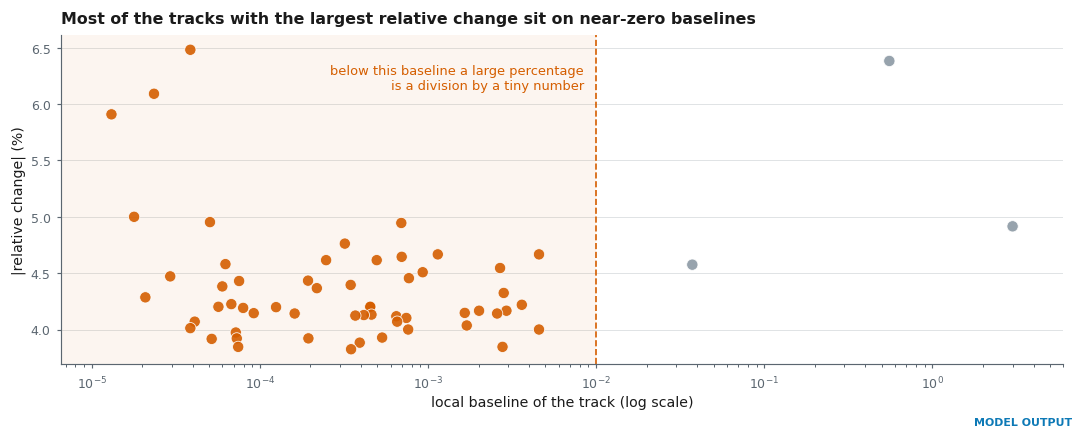

> **Robustness figure · a relative % misleads when the baseline is near zero**  
> `EXP-009` · figure class `MODEL_OUTPUT`, scientific figure · evidence origin `PREDICTED`  
> *What is observed.* each point is one of the tracks with the largest relative change. Those producing large percentages have baselines close to zero: the percentage is an artefact of the division, not a signal.  
> **Scope of the result.** that there is no effect in any tissue. It is an argument about the METRIC, not an exhaustive tissue-by-tissue search.  
> provenance: `work/alphagenome/*_tracks.json`

In [8]:
TR = glob.glob("work/alphagenome/chr*_tracks.json")[0]
tr = json.load(io.open(TR, encoding="utf-8"))
top = [t for t in tr.get("top_rel", []) if t.get("rloc")]
if top:
    fig, ax = plt.subplots(figsize=(9.0, 3.6))
    rels = [abs(t["rel"]) * 100 for t in top]
    bases = [t["rloc"] for t in top]
    ax.axvspan(1e-6, 0.01, color=fl.DEAD, alpha=0.06, lw=0)
    ax.scatter(bases, rels, s=46, c=[fl.DEAD if b < 0.01 else fl.FLOW for b in bases],
               alpha=0.9, edgecolor="white", lw=0.5)
    ax.set_xscale("log"); ax.set_xlim(min(bases) / 2, max(bases) * 2)
    ax.set_xlabel("local baseline of the track (log scale)")
    ax.set_ylabel("|relative change| (%)")
    ax.axvline(0.01, color=fl.DEAD, ls="--", lw=1)
    ax.text(0.0085, max(rels) * 0.98, "below this baseline a large percentage\n"
            "is a division by a tiny number", fontsize=7.8, color=fl.DEAD, ha="right", va="top")
    ax.grid(axis="y")
    fl.title(ax, "Most of the tracks with the largest relative change sit on near-zero baselines")
    fl.done(fig, "Robustness figure · a relative % misleads when the baseline is near zero",
            "EXP-009", "PREDICTED", "MODEL_OUTPUT",
            "each point is one of the tracks with the largest relative change. Those producing "
            "large percentages have baselines close to zero: the percentage is an artefact of "
            "the division, not a signal.",
            "that there is no effect in any tissue. It is an argument about the METRIC, not an "
            "exhaustive tissue-by-tissue search.",
            prov="work/alphagenome/*_tracks.json")
else:
    print("  no individual tracks in the file; the argument stays in the text")

## The structural search: GO 2B on the full alignment

This notebook first closed with the structural branch **blocked**: only a pilot lane existed.
GO 2B then rebuilt the full-depth alignment from all four lanes and ran the preregistered
structural callers. Its figures are read from frozen artifacts and fail closed on a hash
mismatch; they carry case-specific breakpoint context, so they are linked here rather than
embedded in this sanitised notebook.

| Class of second allele | Assay (GO 2B) | What can be said, verbatim ceiling |
|---|---|---|
| Copy-number change | CNVpytor RD+BAF | *CNVpytor did not emit an RD+BAF CNV overlapping the BUB1B gene body* |
| Mobile-element insertion | xTea + SCRAMble | *No xTea or SCRAMble MEI call overlapped the BUB1B gene body* |
| Other SVs nearby | Manta + DELLY, adjudicated | None of the alternative loci overlaps the gene body or the two prioritised positions ([MEI/SV map](../figures/pub/fig11_mei_sv_adjudication_map.svg)) |
| Breakpoint signal at the locus | read-level metrics, gene body vs flanks | Reported side by side; **no excess/no-excess threshold was defined** ([read-level assay](../figures/pub/fig10_bub1b_readlevel_assay.svg)) |
| Both prioritised alleles | read-backed re-genotyping (EXP-025) | Recovered in the reads: technical replication |
| Complex insertion | short reads | **Not excluded** |

The regulatory SNV/indel branch and the structural branch are therefore both closed **within
their protocols**. The case is not closed: the lesion that has hidden second alleles in this
disease before, a complex intronic insertion, is exactly the class short reads cannot exclude.

## Decision

| Branch | Status |
|---|---|
| **Regulatory SNV/indel second allele** | **Negative** within the evaluated scope |
| **Structural second allele (CNV, MEI, SV)** | **Not detected** by the GO 2B callers; complex insertion **not excluded** |

**The exact wording:** *No candidate survived population filtering plus global and track-level
AlphaGenome interrogation; no CNV or MEI call from the preregistered GO 2B callers overlapped
the BUB1B gene body.*

**Not:** "AlphaGenome showed that there is no second allele", or "structural variation was
excluded".

### Falsifier

RNA-seq showing aberrant splicing or allelic imbalance of `BUB1B`, or targeted long reads across
the gene body revealing an insertion. Either would supply the second allele this search could
not see. They become the priority only if phase turns out *cis* or the missense proves normal
in a functional assay.

### Next

`05_RESIDUAL_PHENOTYPE`. If the second allele does not appear, could part of the phenotype not
be `BUB1B` at all?